In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error

try:
    from sklearn.metrics import root_mean_squared_error
    def calc_rmse(y_true, y_pred):
        return root_mean_squared_error(y_true, y_pred)
except ImportError:
    from sklearn.metrics import mean_squared_error
    def calc_rmse(y_true, y_pred):
        return np.sqrt(mean_squared_error(y_true, y_pred))

# Load California Housing Dataset
data = fetch_california_housing(as_frame=True)
df = pd.concat([data.data, data.target.rename("HousePrice")], axis=1)

print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
df.head()

Shape: (20640, 9)
Missing values:
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
HousePrice    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HousePrice
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
X = df.drop("HousePrice", axis=1)
y = df["HousePrice"]

# Split BEFORE fitting scaler so test data statistics never leak into training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")

Training samples: 16512, Testing samples: 4128


In [ ]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression (alpha=1.0)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, random_state=42))
    ]),
    "Decision Tree (max_depth=5)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeRegressor(max_depth=5, random_state=42))
    ]),
    "Decision Tree (max_depth=10)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeRegressor(max_depth=10, random_state=42))
    ])
}

records = []
trained_pipelines = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)

    records.append({
        "Model": name,
        "Train RMSE": calc_rmse(y_train, train_pred),
        "Test RMSE": calc_rmse(y_test, test_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

results_df = pd.DataFrame(records).sort_values(by="Test RMSE", ascending=True).reset_index(drop=True)
results_df

,Model,Train RMSE,Test RMSE,Test MAE,Train R2,Test R2
0,Decision Tree (max_depth=10),0.469964,0.644242,0.433044,0.834778,0.683269
1,Decision Tree (max_depth=5),0.695948,0.724234,0.522259,0.637679,0.599732
2,Ridge Regression (alpha=1.0),0.719676,0.745557,0.533193,0.612551,0.575816
3,Linear Regression,0.719676,0.745581,0.533200,0.612551,0.575788


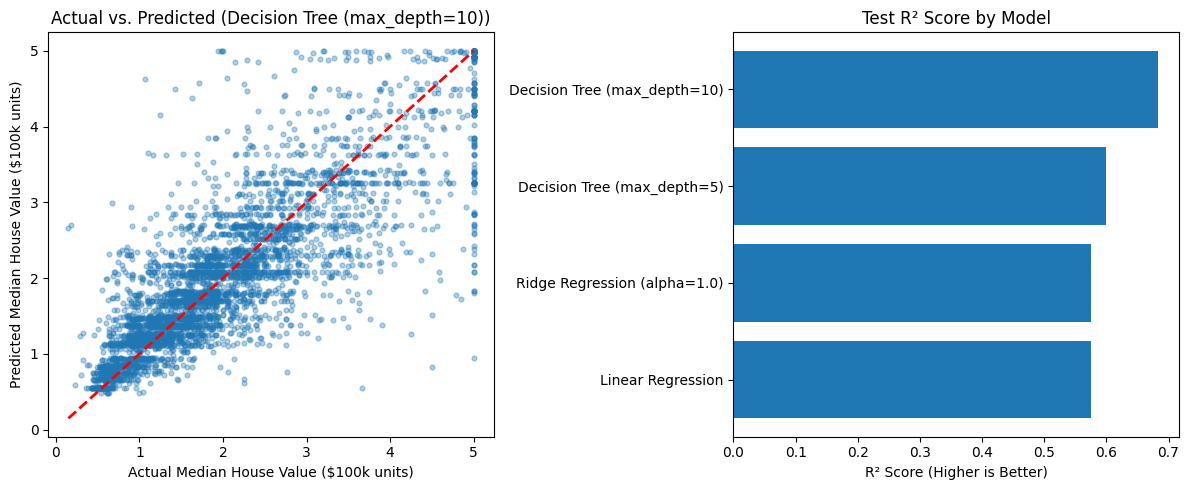

Saved best model: Decision Tree (max_depth=10) -> best_house_price_model.joblib


In [ ]:
# Pick the model with lowest Test RMSE
best_model_name = results_df.loc[0, "Model"]
best_pipe = trained_pipelines[best_model_name]
y_pred_best = best_pipe.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_test, y_pred_best, alpha=0.35, s=12)
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2)
axes[0].set_title(f"Actual vs. Predicted ({best_model_name})")
axes[0].set_xlabel("Actual Median House Value ($100k units)")
axes[0].set_ylabel("Predicted Median House Value ($100k units)")

# Plot 2: Model Test R2 Comparison
axes[1].barh(results_df["Model"], results_df["Test R2"])
axes[1].set_title("Test R² Score by Model")
axes[1].set_xlabel("R² Score (Higher is Better)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# Optional deliverable: Save best model pipeline
joblib.dump(best_pipe, "best_house_price_model.joblib")
print(f"Saved best model: {best_model_name} -> best_house_price_model.joblib")